# 06 · Resumen de resultados: voz y texto para depresión y ansiedad

- **Muestra**: 352 adolescentes de desarrollo (194 mujeres, 158 hombres). La prueba final sellada (89) no se usó.
- **Desenlaces**: depresión = PHQ-9 ≥ 15 (67 casos); ansiedad = GAD-7 ≥ 10 (104 casos).
- **Tareas**: P1 = "lo mejor que te ha pasado", P2 = "lo peor que te ha pasado", P1+P2 = ambas.
- **Modelo**: un solo modelo para ambos sexos. Ramas (random forest para el audio, logística para el texto) combinadas
  por stacking con una rama de solo sexo. Las ramas no reciben el sexo como predictor.
- **Evaluación**: CV anidada, 5 pliegues × 5 repeticiones (externa) y 3 pliegues (hiperparámetros). AUC = media ± DE
  de los 25 pliegues.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

OUT = Path("outputs")
res = pd.read_csv(OUT / "mm_resumen.csv")
sens = pd.read_csv(OUT / "mm_sensibilidad.csv")
perm = pd.read_csv(OUT / "mm_permutacion.csv")
el = json.loads((OUT / "mm_elegidas.json").read_text())

CONJ = ["P1", "P2", "P1+P2"]
DES = {"dep": "Depresión (PHQ-9 ≥ 15)", "ans": "Ansiedad (GAD-7 ≥ 10)"}
MODELOS = {
    "sexo": "Solo sexo (referencia)",
    "fusion-ss:sexo+espectral": "Sexo + espectral",
    "fusion-ss:sexo+prosodia": "Sexo + prosodia",
    "fusion-ss:tardia_audio": "Sexo + audio (espectral + prosodia)",
    "fusion-ss:sexo+texto": "Sexo + texto",
    "fusion-ss:tardia_audio+texto": "Sexo + audio + texto",
    "fusion-ss:sexo+contexto": "Sexo + contexto del cuestionario",
    "fusion-ss:tardia_audio+texto+contexto": "Sexo + audio + texto + contexto",
}
coma = lambda x: f"{x:.3f}".replace(".", ",")

def pivote(df, valor):
    d = df[df["capa"].isin(MODELOS)].copy()
    d["Modelo"] = d["capa"].map(MODELOS)
    t = d.pivot_table(index="Modelo", columns=["objetivo", "conjunto"], values=valor, aggfunc="first")
    t = t.reindex(index=list(MODELOS.values()), columns=[(o, c) for o in DES for c in CONJ])
    t.columns = pd.MultiIndex.from_tuples([(DES[o], c) for o, c in t.columns])
    return t

## 1. Tabla principal: AUC por modelo, desenlace y tarea

In [2]:
auc, de = pivote(res, "auc"), pivote(res, "auc_de")
texto = auc.map(coma) + " ± " + de.map(coma)

def resaltar(col):
    v = auc[col.name]
    mejor = v.drop("Solo sexo (referencia)").drop([i for i in v.index if "contexto" in i]).idxmax()
    return ["font-weight: bold; background-color: #d9ead3" if i == mejor else "" for i in col.index]

(texto.style.apply(resaltar, axis=0)
      .set_caption("AUC (media ± DE de 25 pliegues). En verde, el mejor modelo de voz y texto por columna "
                   "(sin contar los que usan el cuestionario).")
      .set_table_styles([{"selector": "th", "props": "text-align: center"}]))

**Lectura.** En depresión, voz + texto llega a **0,69** frente a **0,60** del sexo solo. La señal está en P2 y en
P1+P2; P1 sola casi no agrega. En ansiedad nada se separa con claridad del sexo (0,58). El contexto del cuestionario
(motivación, satisfacción escolar, consumo) es lo más alto, pero es autorreporte del mismo instrumento que PHQ-9 y
GAD-7.

## 2. ¿Cuánto agrega cada capa sobre el sexo solo?

In [3]:
d, p = pivote(res, "dauc_vs_sexo"), pivote(res, "p_vs_sexo")
tabla = d.map(lambda x: f"{x:+.3f}".replace(".", ",")) + p.map(lambda x: " (p " + coma(x) + ")")
tabla = tabla.drop("Solo sexo (referencia)")

def marcar(col):
    return ["color: #1a7f37; font-weight: bold" if v < 0.05 else "color: #888" for v in p.drop("Solo sexo (referencia)")[col.name]]

tabla.style.apply(marcar, axis=0).set_caption(
    "ΔAUC frente al modelo de solo sexo; p de la prueba t corregida de Nadeau–Bengio sobre los 25 pliegues pareados. "
    "En verde, p < 0,05.")

**Lectura.** En depresión, audio y audio + texto agregan de forma consistente en P2 y P1+P2 (+0,07 a +0,09). El texto
solo agrega +0,06, pero no llega a p < 0,05. En ansiedad ninguna capa de voz o texto agrega con claridad.

## 3. Dentro de cada sexo (P1+P2)

In [4]:
q = res[(res["conjunto"] == "P1+P2") & res["capa"].isin(MODELOS)].copy()
q["Modelo"] = q["capa"].map(MODELOS)
filas = []
for o in DES:
    for m in MODELOS.values():
        r = q[(q["objetivo"] == o) & (q["Modelo"] == m)]
        if len(r):
            r = r.iloc[0]
            filas.append({"Desenlace": DES[o], "Modelo": m, "AUC total": coma(r["auc"]),
                          "AUC mujeres": coma(r["auc_mujer"]), "AUC hombres": coma(r["auc_hombre"]),
                          "Exactitud balanceada": coma(r["bal_acc"]), "Sensibilidad": coma(r["sens"]),
                          "Especificidad": coma(r["esp"])})
pd.DataFrame(filas).set_index(["Desenlace", "Modelo"]).style.set_caption(
    "Dentro de un mismo sexo el sexo no puede discriminar (solo sexo ≈ 0,5): estos AUC miden la voz y el texto. "
    "Umbral 0,5 para exactitud, sensibilidad y especificidad.")

**Lectura.** En depresión, voz + texto discrimina igual en mujeres que en hombres (≈ 0,65). En ansiedad, la prosodia
funciona sobre todo en hombres.

## 4. Gráfico: AUC en P1+P2

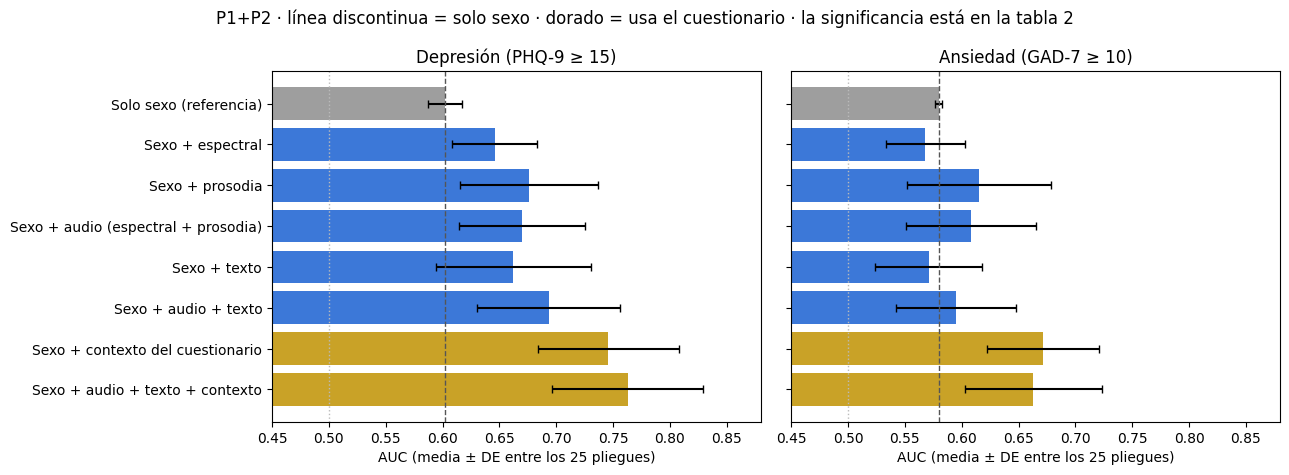

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharex=True)
orden = [m for m in MODELOS.values()][::-1]
for ax, o in zip(axes, DES):
    a = auc[(DES[o], "P1+P2")].reindex(orden)
    e = de[(DES[o], "P1+P2")].reindex(orden)
    colores = ["#9e9e9e" if "sexo (ref" in m else ("#c9a227" if "contexto" in m else "#3c78d8") for m in orden]
    ax.barh(orden, a, xerr=e, color=colores, capsize=3)
    ax.axvline(a["Solo sexo (referencia)"], color="#555", ls="--", lw=1)
    ax.axvline(0.5, color="#bbb", ls=":", lw=1)
    ax.set_xlim(0.45, 0.88)
    ax.set_title(DES[o])
    ax.set_xlabel("AUC (media ± DE entre los 25 pliegues)")
axes[1].set_yticklabels([])
plt.suptitle("P1+P2 · línea discontinua = solo sexo · dorado = usa el cuestionario · la significancia está en la tabla 2")
plt.tight_layout(); plt.show()

## 5. Escala de las ventanas de audio (P1+P2)

In [6]:
ESC = {"glob": "Audio completo", "seg": "Tramos entre pausas", "v1": "Ventanas 1 s", "v5": "Ventanas 5 s",
       "v10": "Ventanas 10 s"}
u = res[(res["conjunto"] == "P1+P2") & res["capa"].str.match(r"^(espectral|prosodia):\w+\|rf$")].copy()
u["Familia"] = u["capa"].str.extract(r"^(\w+):")[0].str.capitalize()
u["Escala"] = u["capa"].str.extract(r":(\w+)\|")[0].map(ESC)
t = u.pivot_table(index=["Familia", "Escala"], columns="objetivo", values="auc")[["dep", "ans"]]
t = t.reindex([(f, ESC[e]) for f in ["Espectral", "Prosodia"] for e in ESC if (f, ESC[e]) in t.index])
t.columns = [DES[c] for c in t.columns]
t.style.format(coma).highlight_max(axis=0, props="font-weight: bold; background-color: #d9ead3").set_caption(
    "AUC de un random forest por familia y escala (con el sexo como variable). Sirve para comparar escalas entre sí. "
    "Cada escala resume las features con su media y su DE entre tramos o ventanas.")

**Lectura.** Las ventanas de 10 s (con solapamiento de 5 s) son la mejor escala en las dos familias; el promedio del
audio completo es la peor. La prosodia rinde más que lo espectral.

## 6. Modelo de texto (P1+P2)

In [7]:
TX = {"beto": "BETO (BERT en español)", "e5": "multilingual-e5-base", "qwen": "Qwen3-Embedding-0.6B"}
MOD = {"lr": "Logística L2", "rfpca": "Random forest sobre PCA"}
x = res[(res["conjunto"] == "P1+P2") & res["capa"].str.match(r"^texto:\w+\|(lr|rfpca)$")].copy()
x["Embedding"] = x["capa"].str.extract(r"texto:(\w+)\|")[0].map(TX)
x["Clasificador"] = x["capa"].str.extract(r"\|(\w+)$")[0].map(MOD)
t = x.pivot_table(index=["Embedding", "Clasificador"], columns="objetivo", values="auc")[["dep", "ans"]]
t.columns = [DES[c] for c in t.columns]
t.style.format(coma).highlight_max(axis=0, props="font-weight: bold; background-color: #d9ead3").set_caption(
    "AUC del texto (embeddings congelados, locales; con el sexo como variable). Transcripción humana o, donde "
    "faltaba, Whisper local.")

**Lectura.** Qwen3-Embedding con logística es el mejor texto; BETO queda por debajo.

## 7. Robustez (P1+P2, sexo + audio + texto)

In [8]:
NOM = {"principal": "Muestra completa", "sin_ceros": "Sin dobles ceros (0 en PHQ-9 y GAD-7)",
       "sin_banderas": "Sin respuestas inconsistentes", "solo_texto_humano": "Solo transcripciones humanas",
       "cortes_alternativos": "Corte alternativo"}
OBJ = {"dep": "Depresión (PHQ-9 ≥ 15)", "ans": "Ansiedad (GAD-7 ≥ 10)", "dep10": "Depresión (PHQ-9 ≥ 10)",
       "dep8": "Depresión (PHQ-8 ≥ 10)"}
todo = pd.concat([res[res["conjunto"] == "P1+P2"], sens])
filas = []
for (mu, o), g in todo.groupby(["muestra", "objetivo"], sort=False):
    g = g.set_index("capa")
    if "fusion:tardia_audio+texto" not in g.index:
        continue
    r = g.loc["fusion:tardia_audio+texto"]
    filas.append({"Muestra": NOM.get(mu, mu), "Desenlace": OBJ.get(o, o), "n (casos)": f"{int(r['n'])} ({int(r['casos'])})",
                  "Solo sexo": coma(g.loc["sexo", "auc"]), "Sexo + audio + texto": coma(r["auc"]),
                  "ΔAUC": f"{r['dauc_vs_sexo']:+.3f}".replace(".", ","), "p": coma(r["p_vs_sexo"])})
t = pd.DataFrame(filas)
t["_o"] = t["Desenlace"].str.startswith("Ansiedad")
t.sort_values(["_o"], kind="stable").drop(columns="_o").set_index(["Desenlace", "Muestra"]).style.set_caption(
    "Cada variante rehace la CV anidada completa (versión con el sexo también dentro de las ramas, que en la muestra "
    "completa da lo mismo: 0,690 frente a 0,693). Dobles ceros: 21 sujetos (15 hombres). Inconsistentes: respuesta "
    "plana en 37 ítems, PHQ-9 discordante con BDI, ítem 9 del PHQ-9 > 0 con C-SSRS = 0.")

**Lectura.** En depresión el resultado se mantiene en todas las variantes (0,67–0,70). En ansiedad no cambia: sigue
sin superar al sexo.

## 8. Prueba de permutación (P1+P2)

In [9]:
pp = perm.copy()
pp["Desenlace"] = pp["objetivo"].map(DES)
pp["Modelo"] = pp["modelo"].str.replace(" (tardia)", "").str.replace(" [ramas sin sexo]", " · ramas sin sexo")
pp = pp[["Desenlace", "Modelo", "auc_obs", "auc_solo_sexo", "nulo_media", "nulo_p95", "p"]]
pp.columns = ["Desenlace", "Modelo", "AUC observado", "AUC solo sexo", "Media del nulo", "Percentil 95 del nulo", "p"]
pp.set_index(["Desenlace", "Modelo"]).style.format(coma).set_caption(
    "100 permutaciones de las etiquetas dentro de cada sexo (el nulo conserva la relación sexo–desenlace). "
    "CV simple de 5 pliegues; p mínimo ≈ 0,01.")

**Lectura.** En depresión, texto y audio + texto superan al nulo (p = 0,01). En ansiedad el resultado de esta prueba
no coincide con el de la CV anidada: queda como no concluyente.

## Resumen

- **Depresión**: voz + texto da AUC 0,69 frente a 0,60 del sexo solo. Funciona igual en mujeres y en hombres y se
  mantiene en todas las pruebas de robustez.
- **Ansiedad**: no concluyente; la prosodia en hombres es lo más prometedor.
- La mejor escala es la ventana de 10 s; el mejor texto es Qwen3-Embedding; P2 concentra la señal.
- La escala y el texto se eligieron con estos mismos datos; la confirmación es la prueba final sellada, con un modelo
  fijado antes de abrirla.